In [61]:
# Ex 1.b
# Ex b.1
import numpy as np

A = np.array([[1.5, 2],
              [2, 4]])

eigenvalues, eigenvectors = np.linalg.eigh(A)

print("Eigenvalues:")
print(eigenvalues)

print("Eigenvectors:")
print(eigenvectors)

Eigenvalues:
[0.39150472 5.10849528]
Eigenvectors:
[[-0.87464248  0.48476853]
 [ 0.48476853  0.87464248]]


In [62]:
print(np.linalg.norm(eigenvectors[:, 0]))
print(np.linalg.norm(eigenvectors[:, 1]))

1.0
1.0


In [63]:
# Ex b.2
x1 = eigenvectors[:, 0]
x2 = eigenvectors[:, 1]

print(np.dot(x1, x2))

-1.6942237973933643e-17


In [64]:
print(np.dot(x1, x1))
print(np.dot(x2, x2))

1.0
1.0


In [65]:
# b.3
x1 = eigenvectors[:, 0]

outer1 = np.outer(x1, x1)
print(outer1)

[[ 0.76499947 -0.42399915]
 [-0.42399915  0.23500053]]


In [66]:
term1 = eigenvalues[0] * outer1
print(term1)

[[ 0.2995009  -0.16599767]
 [-0.16599767  0.09200382]]


In [67]:
x2 = eigenvectors[:, 1]

outer2 = np.outer(x2, x2)
print(outer2)
term2 = eigenvalues[1] * outer2
print(term2)

[[0.23500053 0.42399915]
 [0.42399915 0.76499947]]
[[1.2004991  2.16599767]
 [2.16599767 3.90799618]]


In [68]:
print(term1+term2)
np.allclose(A, term1 + term2)

[[1.5 2. ]
 [2.  4. ]]


True

In [69]:
# Ex 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, log_loss, accuracy_score

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

In [70]:
# Ex 3.a
print("Training data:")
print(train.head())
print(train.shape)

print("\nTest data:")
print(test.head())
print(test.shape)

Training data:
          x  y
0  2.947047  1
1 -2.760971  0
2 -1.859106  0
3 -0.779127  0
4  1.244612  0
(300, 2)

Test data:
          x  y
0 -1.933431  0
1  0.430934  0
2  0.226957  0
3 -2.229210  0
4 -0.016591  1
(100, 2)


In [71]:
X_train = train[["x"]]
y_train = train["y"]

X_test = test[["x"]]
y_test = test["y"]

model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(y_train[:5])
print(y_train_pred[:5])

0    1
1    0
2    0
3    0
4    0
Name: y, dtype: int64
[ 1.19533103 -0.13231213  0.07745508  0.32865028  0.79935701]


In [72]:
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print("Train MSE:", train_mse)
print("Test MSE:", test_mse)

Train MSE: 0.09829825859825463
Test MSE: 0.11020105555582577


/Users/riku.personal/miniconda3/envs/ml1/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


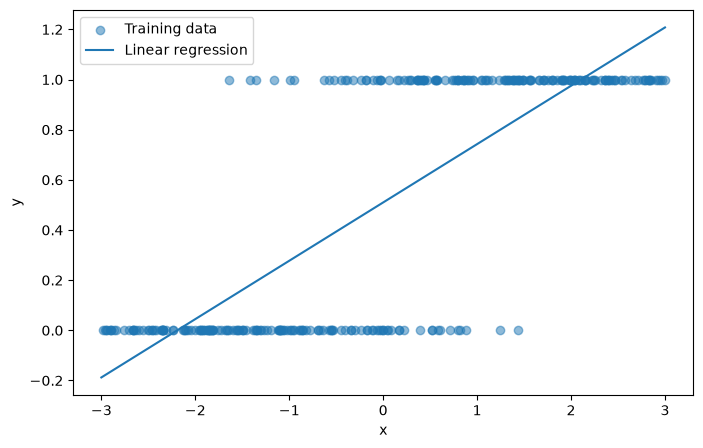

In [73]:
x = np.linspace(start=-3, stop=3, num=100)
y = model.predict(x.reshape(-1, 1))

plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, label="Training data", alpha=0.5)

plt.plot(x, y, "-", label="Linear regression")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [74]:
logistic_model = LogisticRegression(C=np.inf)
logistic_model.fit(X_train, y_train)

logistic_y_train_proba = logistic_model.predict_proba(X_train)
logistic_y_test_proba = logistic_model.predict_proba(X_test)

print(logistic_y_train_proba[:5])
print(logistic_y_test_proba[:5])

[[0.00260872 0.99739128]
 [0.99540012 0.00459988]
 [0.9730911  0.0269089 ]
 [0.80931887 0.19068113]
 [0.07115763 0.92884237]]
[[0.97669406 0.02330594]
 [0.27790234 0.72209766]
 [0.36580678 0.63419322]
 [0.98690345 0.01309655]
 [0.48323015 0.51676985]]


In [75]:
train_logloss = log_loss(y_train, logistic_y_train_proba)
test_logloss = log_loss(y_test, logistic_y_test_proba)

print("Train Log Loss:", train_logloss)
print("Test Log Loss:", test_logloss)

Train Log Loss: 0.28372072605987264
Test Log Loss: 0.31449393505054457


/Users/riku.personal/miniconda3/envs/ml1/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


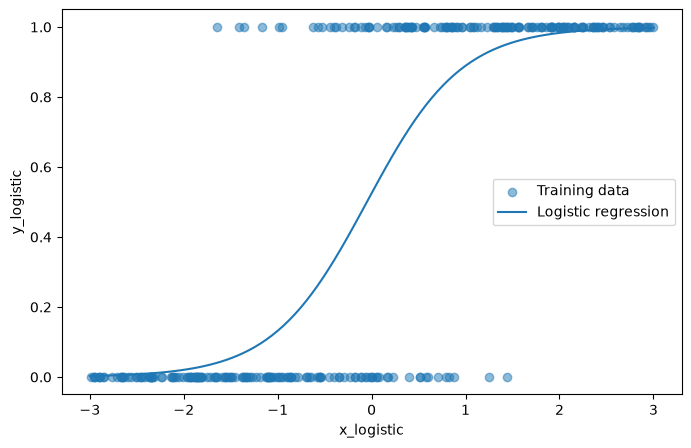

In [76]:
x_logistic = np.linspace(start=-3, stop=3, num=100)
y_logistic = logistic_model.predict_proba(x_logistic.reshape(-1, 1))[:, 1]

plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, label="Training data", alpha=0.5)

plt.plot(x_logistic, y_logistic, "-", label="Logistic regression")

plt.xlabel("x_logistic")
plt.ylabel("y_logistic")
plt.legend()
plt.show()

In [77]:
# Ex 3b
t = 0.5 # baseline threshold for classification 0.83

logistic_predictions = (logistic_y_test_proba[:, 1] >= t).astype(int)
logistic_predictions_test_accuracy = accuracy_score(y_test, logistic_predictions)

print("Test Accuracy:", logistic_predictions_test_accuracy)

Test Accuracy: 0.83


In [78]:
correct = (y_test == logistic_predictions).sum()
total = len(y_test)

manual_accuracy = correct / total

print(correct, total, manual_accuracy)

83 100 0.83


In [81]:
thresholds = np.linspace(0, 1, 1001)
accuracies = {}

for t in thresholds:
    logistic_predictions = (logistic_y_test_proba[:, 1] >= t).astype(int)
    logistic_predictions_test_accuracy = accuracy_score(y_test, logistic_predictions)
    accuracies[float(t)] = logistic_predictions_test_accuracy

print("Top 5 Test Accuracy:", sorted(accuracies.items(), key=lambda x: x[1], reverse=True)[:5])

Top 5 Test Accuracy: [(0.321, 0.87), (0.322, 0.86), (0.323, 0.86), (0.324, 0.86), (0.325, 0.86)]


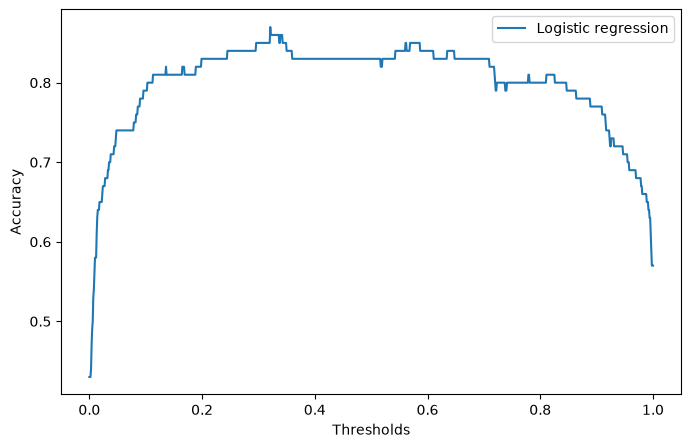

In [82]:
threshold_values = np.array(list(accuracies.keys()))
accuracy_values = np.array(list(accuracies.values()))

plt.figure(figsize=(8, 5))

plt.plot(threshold_values, accuracy_values, "-", label="Logistic regression")

plt.xlabel("Thresholds")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Top 5 Test Accuracy: [(0.41100000000000003, 0.86), (0.41200000000000003, 0.86), (0.41300000000000003, 0.86), (0.41400000000000003, 0.86), (0.41500000000000004, 0.86)]


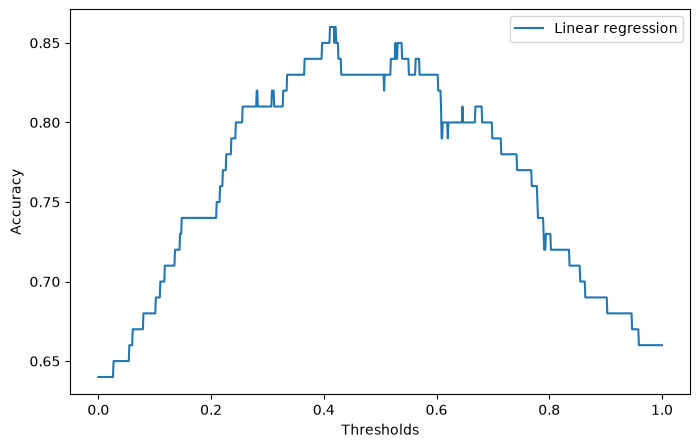

In [84]:
linreg_accuracies = {}

for t in thresholds:
    linreg_predictions = (y_test_pred >= t).astype(int)
    linreg_predictions_test_accuracy = accuracy_score(y_test, linreg_predictions)
    linreg_accuracies[float(t)] = linreg_predictions_test_accuracy

print("Top 5 Test Accuracy:", sorted(linreg_accuracies.items(), key=lambda x: x[1], reverse=True)[:5])

threshold_linreg_values = np.array(list(linreg_accuracies.keys()))
accuracy_linreg_values = np.array(list(linreg_accuracies.values()))

plt.figure(figsize=(8, 5))

plt.plot(threshold_linreg_values, accuracy_linreg_values, "-", label="Linear regression")

plt.xlabel("Thresholds")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

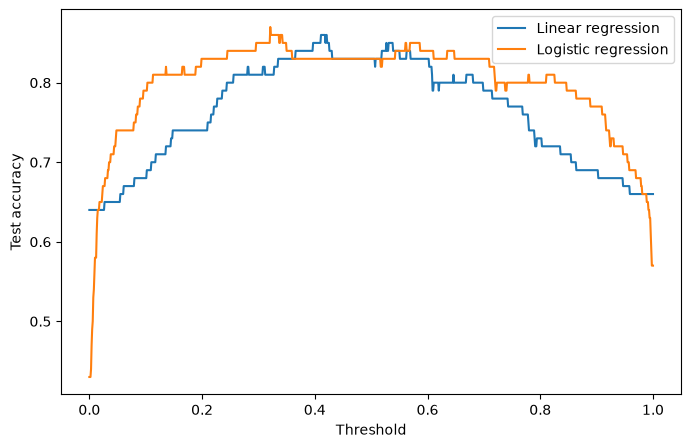

In [85]:
plt.figure(figsize=(8, 5))

plt.plot(threshold_linreg_values, accuracy_linreg_values, label="Linear regression")
plt.plot(threshold_values, accuracy_values, label="Logistic regression")

plt.xlabel("Threshold")
plt.ylabel("Test accuracy")
plt.legend()
plt.show()

In [89]:
probs = logistic_y_test_proba[:, 1]

extreme_mask = (probs < 0.1) | (probs > 0.9)
print("Number of extreme predictions:", extreme_mask.sum())

Number of extreme predictions: 58


In [94]:
t = 0.5 # baseline threshold for classification 0.83

extreme_y_test = y_test[extreme_mask]

logistic_predictions = (logistic_y_test_proba[extreme_mask, 1] >= t).astype(int)
logistic_predictions_test_accuracy = accuracy_score(extreme_y_test, logistic_predictions)

print("Test Accuracy:", logistic_predictions_test_accuracy)

Test Accuracy: 0.9827586206896551


In [108]:
linreg_extreme_mask = (y_test_pred < 0.1) | (y_test_pred > 0.9)
print("Number of extreme predictions:", linreg_extreme_mask.sum())

Number of extreme predictions: 37


In [ ]:
t = 0.5 # baseline threshold for classification 0.83

extreme_linreg_y_test = y_test[linreg_extreme_mask]

linreg_predictions = (y_test_pred[linreg_extreme_mask] >= t).astype(int)

linreg_predictions_test_accuracy = accuracy_score(extreme_linreg_y_test, linreg_predictions)

print("Linreg Test Accuracy:", linreg_predictions_test_accuracy)

Linreg Test Accuracy: 1.0
